## 1. Librerías y GPU

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(len(gpus), "Physical GPUs,", len(tf.config.list_logical_devices('GPU')), "Logical GPUs")
    except RuntimeError as e:
        print(e)
else:
    print("Sin GPU (no es necesaria para este dataset, entrena rápido en CPU)")

1 Physical GPUs, 1 Logical GPUs


## 2. Función para graficar curvas de aprendizaje

In [2]:
def plot_learning_curve(history):
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('Accuracy Curves')
    plt.xlabel('Época')
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.xlabel('Época')
    plt.legend()
    plt.show()

## 3. Cargar el dataset


In [3]:
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = next(iter(uploaded))
except ImportError:
    CSV_PATH = "fitness_poses_csvs_out_full_list__1_.csv"

# El CSV no trae encabezado: col 0 = imagen, col 1 = etiqueta, cols 2..100 = 33 landmarks (x, y, z)
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.iloc[:3, :8]

Saving fitness_poses_csvs_out_full_list.csv to fitness_poses_csvs_out_full_list.csv
(1424, 101)


,0,1,2,3,4,5,6,7
0,01421731.jpg,knee_raises_down,226.30034,321.50558,-397.16367,238.72528,305.45117,-403.60820
1,02401425.jpg,knee_raises_down,300.15940,326.38544,-260.99380,308.67630,312.77313,-278.50183
2,03270295.jpg,knee_raises_down,241.66364,284.34467,-171.29659,250.13864,270.94520,-199.71988


In [4]:
coord_names = [f"{ax}{i}" for i in range(33) for ax in ("x", "y", "z")]
df.columns = ["imagen", "etiqueta"] + coord_names

print("Valores nulos:", df.isna().sum().sum())
print("Imágenes duplicadas:", df['imagen'].duplicated().sum())
print()
df['etiqueta'].value_counts()

Valores nulos: 0
Imágenes duplicadas: 0



,count
etiqueta,
lateral_raises_down,135
lateral_raises_up,126
knee_raises_up,125
shoulder_press_down,119
knee_raises_down,117
shoulder_flexion_up,114
shoulder_press_up,106
leg_raises_up,106
leg_raises_down,100


## 4. Exploración de las clases
La etiqueta combina **ejercicio** y **fase** (`up` / `down`). Las separamos para analizarlas, aunque el modelo se entrena con la etiqueta completa (13 clases).

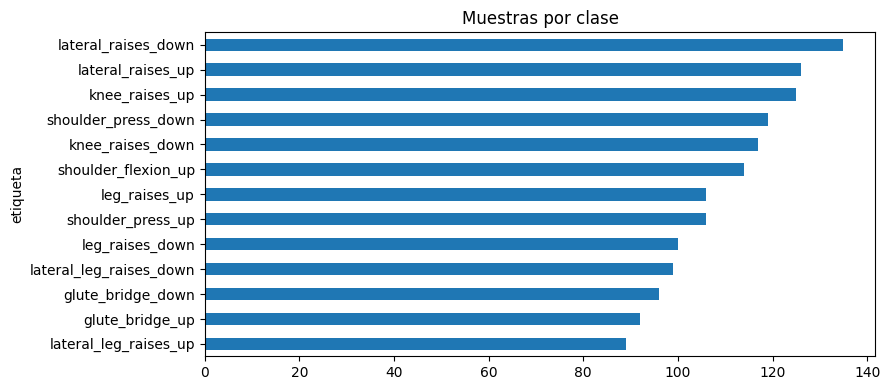

fase,down,up
ejercicio,,
glute_bridge,96.0,92.0
knee_raises,117.0,125.0
lateral_leg_raises,99.0,89.0
lateral_raises,135.0,126.0
leg_raises,100.0,106.0
shoulder_flexion,NaN,114.0
shoulder_press,119.0,106.0


In [5]:
df['ejercicio'] = df['etiqueta'].str.rsplit('_', n=1).str[0]
df['fase'] = df['etiqueta'].str.rsplit('_', n=1).str[1]

plt.figure(figsize=(9, 4))
df['etiqueta'].value_counts().sort_values().plot(kind='barh')
plt.title("Muestras por clase")
plt.tight_layout()
plt.show()

df.groupby('ejercicio')['fase'].value_counts().unstack()

## 5. Preparar los datos
1. Convertimos cada fila a un arreglo `(33, 3)`.
2. **Normalización de pose:** restamos el centro de la cadera (así la pose queda centrada en el origen) y dividimos entre la longitud del torso (así no importa la distancia a la cámara).

Índices MediaPipe: hombros = 11 y 12, caderas = 23 y 24.

In [6]:
X_raw = df[coord_names].to_numpy(dtype=np.float32).reshape(-1, 33, 3)

def normalizar_pose(poses):
    """poses: (N, 33, 3) -> (N, 99) centradas en la cadera y escaladas por el torso."""
    poses = poses.copy()
    cadera = (poses[:, 23] + poses[:, 24]) / 2          # (N, 3)
    hombro = (poses[:, 11] + poses[:, 12]) / 2          # (N, 3)
    poses = poses - cadera[:, None, :]
    torso = np.linalg.norm(hombro - cadera, axis=1)     # (N,)
    poses = poses / np.maximum(torso, 1e-6)[:, None, None]
    return poses.reshape(len(poses), -1)

X = normalizar_pose(X_raw)

encoder = LabelEncoder()
y = encoder.fit_transform(df['etiqueta'])
class_names = list(encoder.classes_)
n_classes = len(class_names)

print("X:", X.shape, "| y:", y.shape, "| clases:", n_classes)
print("Rango antes :", X_raw.min(), "a", X_raw.max())
print("Rango después:", X.min().round(2), "a", X.max().round(2))

X: (1424, 99) | y: (1424,) | clases: 13
Rango antes : -1456.866 a 3231.2917
Rango después: -5.21 a 4.78


## 6. División Train / Validación / Test
70 % / 15 % / 15 %, **estratificada** para que cada conjunto tenga la misma proporción de clases (importante porque el dataset es pequeño).

In [7]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp
)

# Guardamos también las poses crudas del test (las usaremos en el experimento de robustez)
_, tmp_raw, _, _ = train_test_split(X_raw, y, test_size=0.30, random_state=42, stratify=y)
_, X_test_raw, _, _ = train_test_split(tmp_raw, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)

X_train.shape, X_val.shape, X_test.shape

((996, 99), (214, 99), (214, 99))

## 7. Visualizar una pose
Dibujamos el esqueleto normalizado de algunas muestras para confirmar que la normalización tiene sentido.

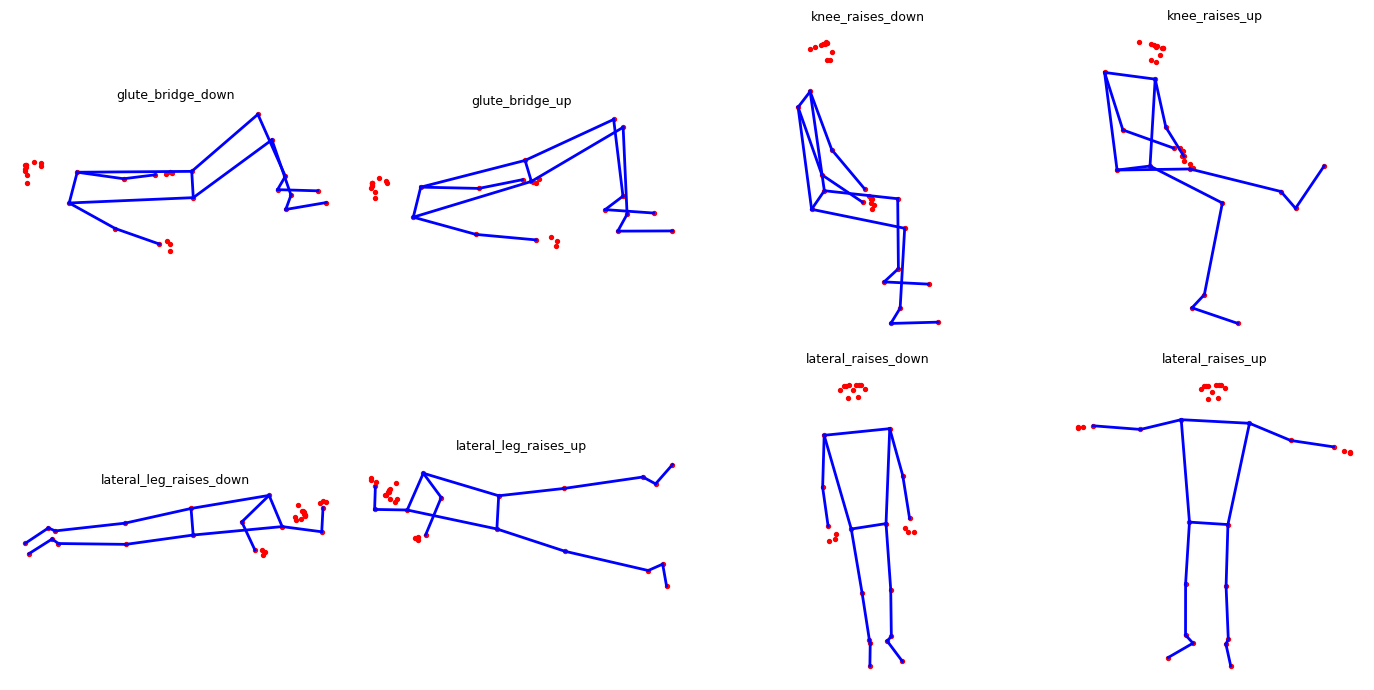

In [8]:
# Conexiones principales del esqueleto de MediaPipe
CONEXIONES = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),(23,24),
              (23,25),(25,27),(24,26),(26,28),(27,29),(29,31),(28,30),(30,32)]

def dibujar_pose(vec99, ax, titulo=""):
    p = vec99.reshape(33, 3)
    for a, b in CONEXIONES:
        ax.plot([p[a,0], p[b,0]], [p[a,1], p[b,1]], 'b-', lw=2)
    ax.scatter(p[:,0], p[:,1], s=8, c='r')
    ax.invert_yaxis()          # en imagen, y crece hacia abajo
    ax.set_aspect('equal')
    ax.set_title(titulo, fontsize=9)
    ax.axis('off')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, clase in zip(axes.ravel(), class_names[:8]):
    idx = np.where(y_train == encoder.transform([clase])[0])[0][0]
    dibujar_pose(X_train[idx], ax, clase)
plt.tight_layout()
plt.show()

## 8. Modelo 1 (MLP)
Misma arquitectura base del notebook de MNIST (128 → 64 → softmax), con `Dropout` y `EarlyStopping` porque tenemos pocas muestras y el sobreajuste llega rápido.

In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(units=n_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 13)             │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,901 (85.55 KB)

 Trainable params: 21,901 (85.55 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=0
)
print(f"Épocas entrenadas: {len(history.history['loss'])}")
print(f"Train acc: {history.history['accuracy'][-1]:.4f} | Val acc: {history.history['val_accuracy'][-1]:.4f}")

Épocas entrenadas: 59
Train acc: 0.9980 | Val acc: 0.9953


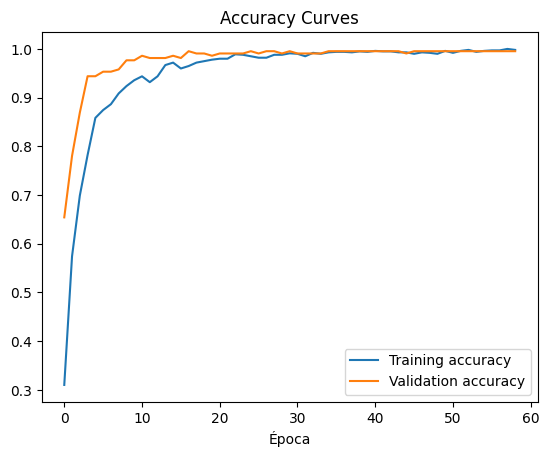

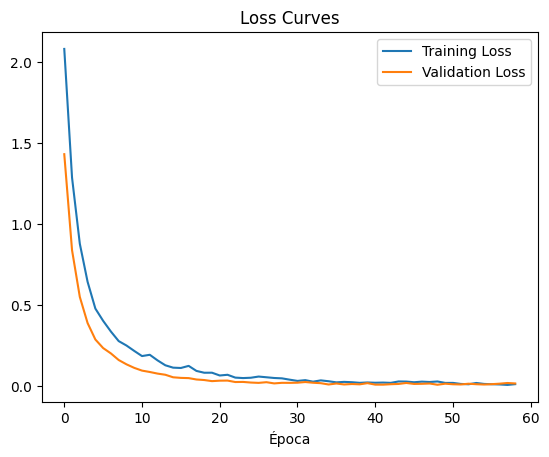

In [11]:
plot_learning_curve(history)

## 9. Evaluación en el conjunto de test

Test accuracy: 0.9953 | Test loss: 0.0120


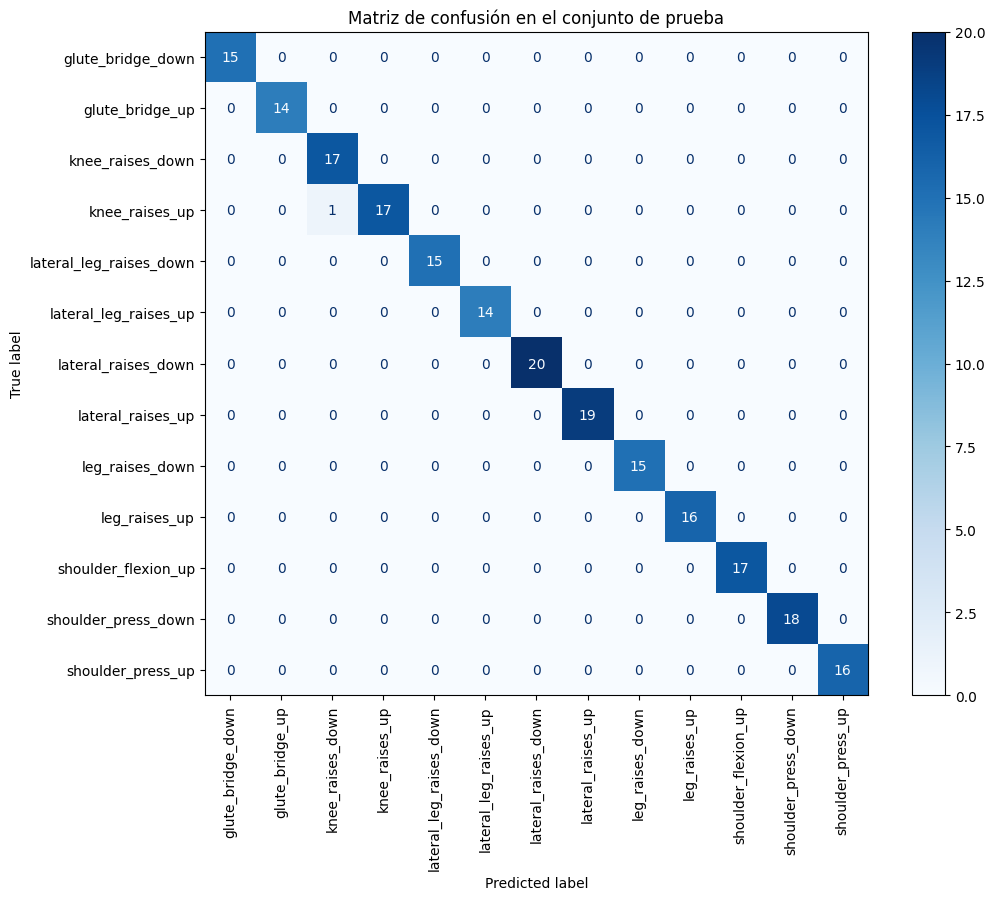

In [12]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

probabilidades = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap="Blues", ax=ax, xticks_rotation=90
)
plt.title("Matriz de confusión en el conjunto de prueba")
plt.grid(False)
plt.tight_layout()
plt.show()

In [13]:
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

                         precision    recall  f1-score   support

      glute_bridge_down      1.000     1.000     1.000        15
        glute_bridge_up      1.000     1.000     1.000        14
       knee_raises_down      0.944     1.000     0.971        17
         knee_raises_up      1.000     0.944     0.971        18
lateral_leg_raises_down      1.000     1.000     1.000        15
  lateral_leg_raises_up      1.000     1.000     1.000        14
    lateral_raises_down      1.000     1.000     1.000        20
      lateral_raises_up      1.000     1.000     1.000        19
        leg_raises_down      1.000     1.000     1.000        15
          leg_raises_up      1.000     1.000     1.000        16
    shoulder_flexion_up      1.000     1.000     1.000        17
    shoulder_press_down      1.000     1.000     1.000        18
      shoulder_press_up      1.000     1.000     1.000        16

               accuracy                          0.995       214
              macro avg

In [14]:
ej_real = np.array([class_names[i].rsplit('_', 1)[0] for i in y_test])
ej_pred = np.array([class_names[i].rsplit('_', 1)[0] for i in y_pred])
print(f"Accuracy por ejercicio (sin fase): {(ej_real == ej_pred).mean():.4f}")
print(f"Accuracy por clase completa     : {(y_test == y_pred).mean():.4f}")

Accuracy por ejercicio (sin fase): 1.0000
Accuracy por clase completa     : 0.9953


## 10. Predicción de una muestra individual

Real     : leg_raises_down
Predicho : leg_raises_down (1.00)


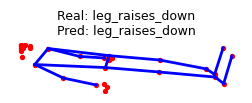

In [15]:
i = 0
muestra = X_test[i].reshape(1, -1)
probs = model.predict(muestra, verbose=0)[0]
pred = np.argmax(probs)

print("Real     :", class_names[y_test[i]])
print("Predicho :", class_names[pred], f"({probs[pred]:.2f})")

fig, ax = plt.subplots(figsize=(3, 4))
dibujar_pose(X_test[i], ax, f"Real: {class_names[y_test[i]]}\nPred: {class_names[pred]}")
plt.show()

## 11. Experimento de robustez (equivalente al desplazamiento de MNIST)
En MNIST, desplazar la imagen 10 píxeles rompía al MLP. Aquí hacemos lo mismo con las poses: **movemos** la persona 300 px y la **acercamos** a la cámara (×1.5). Comparamos:

- **Modelo con normalización** (el nuestro): debería dar casi lo mismo.
- **Modelo sin normalizar** (entrenado con coordenadas crudas estandarizadas): se espera que falle.

In [16]:
# Modelo de contraste: entrenado con coordenadas crudas
raw_train_idx = train_test_split(np.arange(len(X_raw)), test_size=0.30, random_state=42, stratify=y)[0]
Xr_train = X_raw[raw_train_idx].reshape(len(raw_train_idx), -1)
mu, sd = Xr_train.mean(0), Xr_train.std(0) + 1e-6
estandarizar = lambda a: (a.reshape(len(a), -1) - mu) / sd

model_raw = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(99,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(n_classes, activation="softmax")
])
model_raw.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_raw.fit(estandarizar(X_raw[raw_train_idx]), y_train, epochs=150, batch_size=32,
              validation_data=(estandarizar(X_test_raw), y_test),
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
              verbose=0)

# Perturbación: desplazar y escalar la pose
perturbadas = X_test_raw * 1.5
perturbadas[:, :, 0] += 300
perturbadas[:, :, 1] += 300

acc = lambda m, a: (np.argmax(m.predict(a, verbose=0), 1) == y_test).mean()
resultados = {
    "Con normalización": (acc(model, normalizar_pose(X_test_raw)), acc(model, normalizar_pose(perturbadas))),
    "Sin normalización": (acc(model_raw, estandarizar(X_test_raw)), acc(model_raw, estandarizar(perturbadas))),
}
for nombre, (a_orig, a_pert) in resultados.items():
    print(f"{nombre:18s} | original: {a_orig:.3f} | desplazada+escalada: {a_pert:.3f}")

Con normalización  | original: 0.995 | desplazada+escalada: 0.995
Sin normalización  | original: 0.995 | desplazada+escalada: 0.967


## 12. Modelo 2: espacio latente 2D


In [17]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"),
    tf.keras.layers.Dense(units=n_classes, activation="softmax")
])
model2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history2 = model2.fit(
    X_train, y_train, epochs=60, batch_size=32,
    validation_data=(X_val, y_val), verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
)
print("Val accuracy modelo 2D:", max(history2.history['val_accuracy']))

Val accuracy modelo 2D: 0.9579439163208008


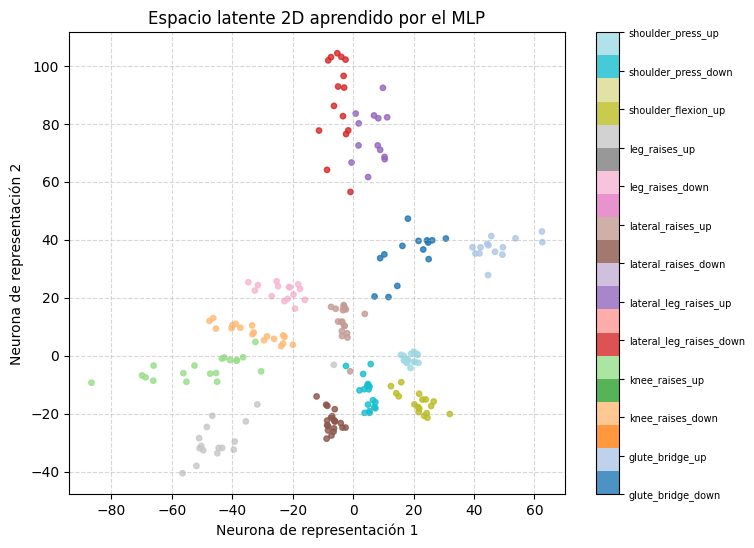

In [18]:
extractor = tf.keras.Model(inputs=model2.inputs, outputs=model2.get_layer("rep_2d").output)
puntos2d = extractor.predict(X_val, verbose=0)

plt.figure(figsize=(8, 6))
sc = plt.scatter(puntos2d[:, 0], puntos2d[:, 1], c=y_val, cmap="tab20", s=15, alpha=0.8)
cbar = plt.colorbar(sc, ticks=range(n_classes))
cbar.ax.set_yticklabels(class_names, fontsize=7)
plt.title("Espacio latente 2D aprendido por el MLP")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 13. Guardar el modelo para la página web
Se guarda el modelo y la lista de clases. También se incluyen los parámetros de normalización, que **la web debe replicar** antes de llamar al modelo (centrar en la cadera y dividir entre el torso).

In [19]:
model.save("modelo_ejercicios.keras")
with open("clases.json", "w") as f:
    json.dump(class_names, f)

print("Guardado: modelo_ejercicios.keras y clases.json")

# Descarga automática en Colab
try:
    from google.colab import files
    files.download("modelo_ejercicios.keras")
    files.download("clases.json")
except ImportError:
    pass

# Opcional: convertir a TensorFlow.js para correrlo directo en el navegador lo dejo por las dudas
# !pip install -q tensorflowjs
# !tensorflowjs_converter --input_format=keras modelo_ejercicios.keras tfjs_modelo/

Guardado: modelo_ejercicios.keras y clases.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Exportar a ONNX (para el backend en .NET)
Para que el backend no tenga que reimplementar la normalización, la **incluyo dentro del grafo ONNX**:

- **Entrada:** `landmarks` con forma `[N, 33, 3]` (los 33 puntos de MediaPipe en x, y, z, **en las mismas unidades que el CSV**.
- **Salida:** `[N, 13]` con las probabilidades de cada clase (el orden está en `clases.json`).

Dentro del modelo se centra la pose en la cadera, se divide entre el torso y se pasa por el MLP entrenado.

In [20]:
!pip install -q tf2onnx onnx onnxruntime

In [21]:
import tf2onnx
import onnxruntime as ort

@tf.function(input_signature=[tf.TensorSpec([None, 33, 3], tf.float32, name="landmarks")])
def modelo_con_preprocesamiento(landmarks):
    cadera = (landmarks[:, 23, :] + landmarks[:, 24, :]) / 2
    hombro = (landmarks[:, 11, :] + landmarks[:, 12, :]) / 2
    centrado = landmarks - cadera[:, None, :]
    torso = tf.norm(hombro - cadera, axis=1)
    escalado = centrado / tf.maximum(torso, 1e-6)[:, None, None]
    return model(tf.reshape(escalado, [-1, 99]), training=False)

tf2onnx.convert.from_function(
    modelo_con_preprocesamiento,
    input_signature=modelo_con_preprocesamiento.input_signature,
    opset=13,
    output_path="modelo_ejercicios.onnx"
)
print("Guardado: modelo_ejercicios.onnx")

Guardado: modelo_ejercicios.onnx


### Validar que el ONNX da lo mismo que Keras
Le pasamos poses **crudas** (sin normalizar) al ONNX y poses normalizadas a Keras: deben coincidir.

In [22]:
sesion = ort.InferenceSession("modelo_ejercicios.onnx")
nombre_in  = sesion.get_inputs()[0].name
nombre_out = sesion.get_outputs()[0].name
print("Entrada:", nombre_in, sesion.get_inputs()[0].shape)
print("Salida :", nombre_out, sesion.get_outputs()[0].shape)

probs_onnx  = sesion.run([nombre_out], {nombre_in: X_test_raw.astype(np.float32)})[0]
probs_keras = model.predict(X_test, verbose=0)

print("Diferencia máxima ONNX vs Keras:", np.abs(probs_onnx - probs_keras).max())
print("Predicciones idénticas:", (probs_onnx.argmax(1) == probs_keras.argmax(1)).mean())
print("Accuracy ONNX en test:", (probs_onnx.argmax(1) == y_test).mean())

Entrada: landmarks ['unk__47', 33, 3]
Salida : Identity:0 ['unk__48', 13]
Diferencia máxima ONNX vs Keras: 3.5762787e-07
Predicciones idénticas: 1.0
Accuracy ONNX en test: 0.9953271028037384


In [23]:
# clases.json ya se guardó arriba; lo volvemos a guardar por las dudas
with open("clases.json", "w") as f:
    json.dump(class_names, f)

try:
    from google.colab import files
    files.download("modelo_ejercicios.onnx")
    files.download("clases.json")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Dejamos una función de ángulos como punto de partida.

In [24]:
def angulo(a, b, c):
    """Ángulo en grados en el punto b, formado por a-b-c (cada punto es un vector xyz)."""
    ba, bc = a - b, c - b
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-9)
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

# Índices MediaPipe: cadera 23/24, rodilla 25/26, tobillo 27/28, hombro 11/12, codo 13/14, muñeca 15/16
def angulos_clave(vec99):
    p = vec99.reshape(33, 3)
    return {
        "rodilla_izq": angulo(p[23], p[25], p[27]),
        "rodilla_der": angulo(p[24], p[26], p[28]),
        "codo_izq":    angulo(p[11], p[13], p[15]),
        "codo_der":    angulo(p[12], p[14], p[16]),
        "cadera_izq":  angulo(p[11], p[23], p[25]),
        "cadera_der":  angulo(p[12], p[24], p[26]),
    }

# Rango típico de cada ángulo por clase (media ± desviación) en el set de entrenamiento
tabla = pd.DataFrame([angulos_clave(v) for v in X_train])
tabla['clase'] = [class_names[i] for i in y_train]
tabla.groupby('clase').mean().round(1)

,rodilla_izq,rodilla_der,codo_izq,codo_der,cadera_izq,cadera_der
clase,,,,,,
glute_bridge_down,59.200001,61.000000,146.399994,144.899994,131.699997,131.699997
glute_bridge_up,61.299999,63.700001,152.399994,159.399994,157.800003,157.600006
knee_raises_down,80.699997,84.000000,122.000000,117.099998,84.800003,86.400002
knee_raises_up,128.899994,127.800003,114.599998,112.900002,99.099998,98.099998
lateral_leg_raises_down,147.800003,148.800003,87.900002,104.900002,161.199997,163.899994
lateral_leg_raises_up,147.100006,150.000000,97.400002,101.500000,157.699997,157.399994
lateral_raises_down,125.800003,131.899994,104.599998,113.800003,155.899994,160.199997
lateral_raises_up,141.399994,141.000000,122.699997,122.000000,158.000000,158.399994
leg_raises_down,167.199997,166.500000,138.600006,146.100006,165.100006,162.000000
